# 03. 이상치 점검

3단계에서 넘겨받은 두 가지 문제의 원인을 확인하는 노트북입니다.

1. 점포당 분기 매출이 100만 원도 안 되는 상권 53곳
2. 점포당 분기 매출이 2위의 두 배 가까이 되는 시청역_8번

여기서는 원인만 확인하고 처리 방법을 고릅니다. 가설 검증(상관, 회귀)은 하지 않습니다.
처리 규칙을 가설 검증 결과를 보고 나서 정하면 원하는 결론이 나오게 데이터를 고르는 셈이 되기 때문입니다.
그래서 이 노트북에는 직장인구나 유동인구와 매출의 관계를 보는 코드가 없습니다.

확인하는 방법은 세 가지입니다.
- 관계가 있어야 하는 다른 컬럼과 맞춰 보기 (매출 금액 ↔ 결제 건수)
- 같은 상권의 다른 분기 값 보기
- 상권 유형처럼 상권의 성격 보기

각 코드 셀 밑의 "코드 읽기"에 줄마다 무슨 일을 하는지 적어 뒀습니다.

In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

load_dotenv('../.env')
url = URL.create(
    drivername='postgresql+psycopg2',
    username=os.environ['PGUSER'],
    password=os.environ['PGPASSWORD'],
    host=os.environ['PGHOST'],
    port=int(os.environ['PGPORT']),
    database=os.environ['PGDATABASE'],
)
engine = create_engine(url)

#### 코드 읽기
- `import ...`: 쓸 라이브러리를 불러옵니다. 02 노트북과 같고 이번에는 numpy와 `text`를 안 써서 뺐습니다.
- `plt.rcParams[...]` 두 줄: 그래프에 한글이 네모로 깨지지 않게 맥 기본 한글 폰트를 지정하고, 마이너스 기호가 깨지는 것도 막습니다.
- `load_dotenv('../.env')`: `.env` 파일에 적어 둔 DB 접속 정보를 환경 변수로 읽어 옵니다. 노트북이 `notebooks/` 안에 있어서 한 칸 위(`../`)를 봅니다.
- `URL.create(...)`: 접속 정보를 하나씩 넣어 접속 주소를 만듭니다. 비밀번호에 특수문자가 있어도 알아서 처리해 줍니다.
- `create_engine(url)`: 이 주소로 DB에 연결할 준비를 합니다. 실제 연결은 `pd.read_sql`을 부를 때 일어납니다.

## 0. 데이터 불러오기

In [2]:
df = pd.read_sql('SELECT * FROM 분석_상권분기', engine)

# 매출이 비공개인 줄은 이번 점검과 상관없어서 뺌
df = df[df['매출'].notna()].copy()

# 객단가 = 결제 한 번에 평균 얼마를 썼는지
df['객단가'] = df['매출'] / df['매출_건수']

# 점포당 건수 = 점포 하나에 분기 동안 결제가 몇 번 잡혔는지
df['점포당_건수'] = df['매출_건수'] / df['점포_수']

# 100만 원 미만을 "저매출"로 표시 (3단계에서 본 기준 그대로)
df['저매출'] = df['점포당_매출'] < 1000000

print(df.shape)

(23568, 31)


#### 코드 읽기
- `pd.read_sql(...)`: 3단계에서 만든 분석 테이블 전체를 데이터프레임으로 가져옵니다.
- `df[df['매출'].notna()]`: `notna()`는 값이 비어 있지 않으면 True입니다. True인 줄만 남겨서 매출이 공개된 줄만 봅니다.
- `.copy()`: 걸러 낸 결과를 새 데이터프레임으로 만듭니다. 이걸 안 붙이면 다음 줄에서 컬럼을 추가할 때 pandas가 경고(SettingWithCopyWarning)를 띄울 수 있습니다.
- `df['객단가'] = ...`: 매출 금액을 결제 건수로 나눠 새 컬럼을 만듭니다. 한 줄 전체에 한 번에 계산됩니다.
- `df['점포당_건수'] = ...`: 결제 건수를 점포 수로 나눕니다. 분기는 약 90일이라 이 값이 90보다 작으면 점포 하나에 하루 1건도 안 잡힌 셈입니다.
- `df['저매출'] = ... < 1000000`: 비교 결과(True/False)를 그대로 컬럼에 넣습니다. True/False 컬럼은 `sum()`을 하면 True 개수가 나와서 세기 편합니다.

## 1. 저매출 53곳: 금액이 작은 건지, 결제가 적게 잡힌 건지

매출 금액은 `결제 건수 × 객단가`입니다. 금액이 작은 이유는 둘 중 하나입니다.
- 객단가가 이상하게 낮다 → 금액 기록 쪽 문제
- 객단가는 보통인데 건수가 거의 없다 → 결제가 잡히는 양 자체가 적은 문제

In [3]:
latest = df[df['기준_년분기_코드'] == 20262].copy()
print('2026Q2 상권 수:', len(latest))
print('저매출 상권 수:', latest['저매출'].sum())

# 저매출(True)과 나머지(False)를 나눠서 중앙값 비교
latest.groupby('저매출')[['객단가', '점포당_건수', '점포_수']].median().round(1)

2026Q2 상권 수: 1058
저매출 상권 수: 53


,객단가,점포당_건수,점포_수
저매출,,,
False,7559.2,2166.8,10.0
True,7659.4,50.9,7.0


#### 코드 읽기
- `df[df['기준_년분기_코드'] == 20262]`: 기준 시점인 2026년 2분기 줄만 남깁니다.
- `latest['저매출'].sum()`: True를 1, False를 0으로 더해서 저매출 상권 수를 셉니다.
- `groupby('저매출')`: 저매출 True 묶음과 False 묶음으로 나눕니다.
- `[['객단가', '점포당_건수', '점포_수']]`: 그중 이 세 컬럼만 봅니다. 대괄호가 두 겹이면 결과가 표(데이터프레임)로 나옵니다.
- `.median()`: 묶음마다 중앙값을 구합니다. 평균은 극단값에 끌려가서 이런 비교에는 중앙값이 낫습니다.

저매출 53곳의 객단가 중앙값은 7,659원으로 나머지 상권(7,559원)과 거의 같습니다. 그런데 점포당 결제 건수 중앙값은 51건으로 나머지(2,167건)의 40분의 1 수준입니다. 한 번 결제할 때 쓰는 돈은 보통이고 결제 횟수만 아주 적은 겁니다. 금액 기록에는 문제가 없어 보입니다. 결제가 거의 잡히지 않는 게 원인입니다.

In [4]:
# 하루 1건도 안 잡히는 곳 = 분기(약 90일) 동안 점포당 90건 미만
latest['하루1건미만'] = latest['점포당_건수'] < 90

pd.crosstab(latest['저매출'], latest['하루1건미만'])

하루1건미만,False,True
저매출,,
False,995,10
True,13,40


#### 코드 읽기
- `latest['하루1건미만'] = ...`: 점포당 건수가 90 미만이면 True인 컬럼을 하나 더 만듭니다.
- `pd.crosstab(행, 열)`: 두 컬럼의 True/False 조합별로 몇 개인지 세는 교차표입니다. 엑셀 피벗 테이블에서 "개수"를 고른 것과 같습니다.

53곳 가운데 40곳은 점포 하나에 하루 1건도 결제가 잡히지 않습니다. 카페 한 곳이 하루에 커피를 한 잔도 못 판다는 뜻이라 실제 영업 상황으로 보기는 어렵습니다. 생각해 볼 수 있는 이유는 두 가지입니다.

- 점포로는 세어지지만 카드 결제는 거의 없는 가게가 섞여 있을 수 있습니다. 간판만 있고 영업은 거의 안 하는 가게가 그런 예입니다.
- 상권 경계에 걸친 가게의 결제가 옆 상권으로 잡혔을 수 있습니다.

둘 다 이 데이터만으로는 확인할 수 없어서 가능성으로만 적어 둡니다.

두 기준이 딱 겹치지는 않습니다. 하루 1건 미만인데 저매출이 아닌 곳이 10곳(객단가가 높은 곳), 저매출인데 하루 1건 이상인 곳이 13곳 있습니다.

In [5]:
cols = ['상권_코드_명', '상권_유형', '점포_수', '매출', '매출_건수', '객단가', '점포당_건수']

low_latest = latest[latest['저매출']]
low_latest.sort_values('점포당_매출')[cols].head(15).round(1)

,상권_코드_명,상권_유형,점포_수,매출,매출_건수,객단가,점포당_건수
20950,경찰병원역 4번(건너말공원),골목상권,6,206602.0,36.0,5738.9,6.0
17885,당곡중학교,골목상권,14,902981.0,66.0,13681.5,4.7
28917,뚝도시장,전통시장,7,465842.0,8.0,58230.2,1.1
14394,개웅초등학교(개웅중학교),골목상권,4,462819.0,16.0,28926.2,4.0
6733,장곡초등학교,골목상권,5,614254.0,51.0,12044.2,10.2
5875,성북초등학교앞,골목상권,9,1181399.0,93.0,12703.2,10.3
17085,상도역 2번,골목상권,9,1196361.0,162.0,7384.9,18.0
607,동대문역 1번,골목상권,9,1213469.0,229.0,5299.0,25.4
31587,남구로시장,전통시장,5,740075.0,86.0,8605.5,17.2
19023,남부터미널역 1번,골목상권,9,1348981.0,176.0,7664.7,19.6


#### 코드 읽기
- `cols = [...]`: 볼 컬럼 이름을 리스트로 정해 둡니다. 컬럼이 28개라 다 보면 화면이 넘칩니다.
- `latest[latest['저매출']]`: `저매출` 컬럼 자체가 True/False라서 그대로 넣으면 True인 줄만 남습니다.
- `.sort_values('점포당_매출')`: 점포당 매출이 작은 순서로 정렬합니다(기본이 오름차순).
- `[cols].head(15).round(1)`: 정해 둔 컬럼만 골라 위에서 15줄을 보고, 소수점은 한 자리로 줄입니다.

맨 위 경찰병원역 4번은 점포 6개에 분기 결제가 36건, 뚝도시장은 점포 7개에 8건입니다. 뚝도시장 객단가가 5만 8천 원으로 튀는 것도 건수가 너무 적어서 생긴 값입니다. 결제가 몇 건 안 되면 한두 건에 객단가나 시간대 비중이 크게 흔들립니다. 이런 상권은 점포당 매출뿐 아니라 오전·점심 비중 같은 지표도 믿기 어렵습니다.

목록은 대부분 골목상권이고 초등학교, 공원, 성당처럼 주거지 안쪽에 있는 상권입니다.

## 2. 저매출 53곳: 늘 낮았는지, 이번 분기만 낮았는지

이번 분기만 낮으면 일시적인 오류일 수 있고, 22개 분기 내내 낮으면 그 상권이 원래 그렇게 잡히는 곳입니다.

In [6]:
low_codes = low_latest['상권_코드']

# 53곳의 모든 분기 줄을 가져옴
history = df[df['상권_코드'].isin(low_codes)]

# 상권마다 매출이 공개된 분기 수, 그중 저매출이었던 분기 수
per_area = history.groupby('상권_코드').agg(
    공개_분기=('저매출', 'count'),
    저매출_분기=('저매출', 'sum'),
)
per_area['저매출_비율'] = per_area['저매출_분기'] / per_area['공개_분기']

per_area['저매출_비율'].describe().round(2)

count    53.00
mean      0.52
std       0.31
min       0.05
25%       0.25
50%       0.50
75%       0.77
max       1.00
Name: 저매출_비율, dtype: float64

#### 코드 읽기
- `low_codes = ...`: 53곳의 상권 코드만 뽑아 둡니다.
- `df['상권_코드'].isin(low_codes)`: 상권 코드가 이 목록 안에 있으면 True입니다. SQL의 `WHERE 상권_코드 IN (...)`과 같습니다.
- `groupby('상권_코드').agg(...)`: 상권마다 묶어서 여러 계산을 한 번에 합니다. `새_컬럼=('대상_컬럼', '계산')` 형식입니다.
  - `count`는 비어 있지 않은 칸의 개수라서 매출이 공개된 분기 수가 됩니다.
  - `sum`은 True 개수라서 저매출이었던 분기 수가 됩니다.
- `per_area['저매출_비율'] = ...`: 저매출 분기 수를 공개 분기 수로 나눕니다. 1이면 공개된 분기 내내 저매출입니다.
- `.describe()`: 개수, 평균, 최솟값, 사분위수, 최댓값을 한 번에 보여 줍니다.

In [7]:
def label(rate):
    if rate >= 0.8:
        return '거의 늘 낮음'
    elif rate >= 0.5:
        return '절반 이상 낮음'
    else:
        return '가끔 낮음'

per_area['구분'] = per_area['저매출_비율'].apply(label)
per_area['구분'].value_counts()

구분
가끔 낮음       25
절반 이상 낮음    16
거의 늘 낮음     12
Name: count, dtype: int64

#### 코드 읽기
- `def label(rate):`: 비율 하나를 받아서 구분 이름을 돌려주는 함수를 만듭니다. 기준(0.8, 0.5)은 보기 쉽게 정한 값이라 엄밀한 의미는 없습니다.
- `.apply(label)`: `저매출_비율` 컬럼의 값 하나하나에 `label` 함수를 적용해서 결과를 새 컬럼에 넣습니다.
- `.value_counts()`: 구분별로 상권이 몇 개인지 셉니다.

53곳 가운데 12곳은 매출이 공개된 분기의 80% 이상이 저매출입니다. 이 상권들은 늘 이렇게 잡히는 곳입니다. 25곳은 절반이 안 되는 분기에만 저매출이었습니다. 같은 상권이라도 분기마다 100만 원을 넘었다 말았다 한다는 뜻입니다.

그래서 2026년 2분기 53곳 목록을 만들어 모든 분기에서 지우는 방식은 맞지 않습니다. 분기마다 같은 규칙을 적용해서 그 분기에 기준에 걸린 줄만 다루는 게 맞습니다.

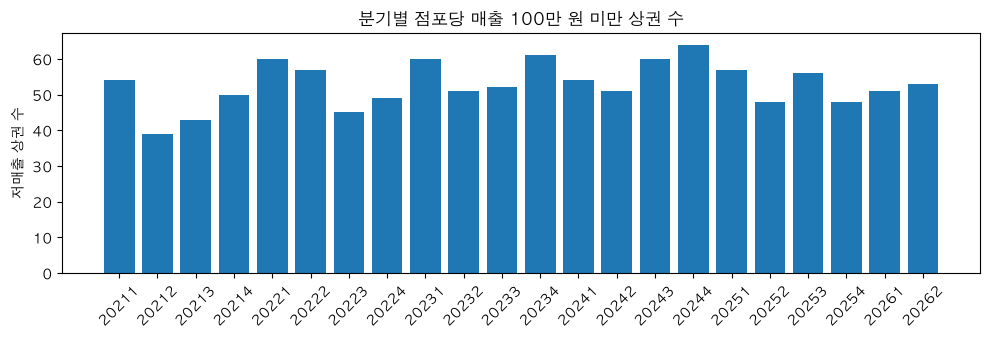

In [8]:
# 서울 전체에서 분기마다 저매출 상권이 몇 곳인지
low_by_quarter = df.groupby('기준_년분기_코드')['저매출'].sum()

labels = [str(q) for q in low_by_quarter.index]
plt.figure(figsize=(10, 3.5))
plt.bar(labels, low_by_quarter.values)
plt.xticks(rotation=45)
plt.ylabel('저매출 상권 수')
plt.title('분기별 점포당 매출 100만 원 미만 상권 수')
plt.tight_layout()
plt.show()

#### 코드 읽기
- `df.groupby('기준_년분기_코드')['저매출'].sum()`: 분기마다 저매출(True)인 상권 수를 셉니다.
- `labels = [str(q) for q in ...]`: 분기 코드(20211 같은 숫자)를 문자로 바꿉니다. 숫자 그대로 두면 matplotlib이 20211과 20221 사이를 숫자 간격으로 벌려서 막대가 띄엄띄엄 찍힙니다.
- `plt.bar(x, 높이)`: 막대그래프를 그립니다.
- `plt.xticks(rotation=45)`: x축 글자를 45도 기울여 겹치지 않게 합니다.
- `plt.tight_layout()`: 제목이나 축 글자가 잘리지 않게 여백을 맞춥니다.

저매출 상권은 22개 분기 내내 39~64곳씩 나옵니다. 특정 분기의 오류로 볼 수 없고 이 데이터에 늘 있는 현상입니다. 4단계에서 여러 분기를 쓰는 분석(H5 순위 안정성, H6 폐업률과 성장률)에서도 같은 규칙이 필요합니다.

## 3. 저매출 53곳: 어떤 상권인지

In [9]:
type_table = pd.crosstab(latest['상권_유형'], latest['저매출'])
type_table['저매출_비율'] = type_table[True] / (type_table[True] + type_table[False])
type_table.round(3)

저매출,False,True,저매출_비율
상권_유형,,,
골목상권,641,46,0.067
발달상권,243,1,0.004
전통시장,121,6,0.047


#### 코드 읽기
- `pd.crosstab(...)`: 상권 유형별로 저매출 True/False가 몇 곳인지 셉니다. 결과 표의 컬럼 이름이 `True`, `False`가 됩니다.
- `type_table[True]`: 따옴표 없이 True를 쓰면 그 컬럼을 가리킵니다. 컬럼 이름이 문자가 아니라 True/False 값이라서 그렇습니다.
- 저매출 비율 = 저매출 상권 수 ÷ (저매출 + 나머지)입니다.

저매출 비율은 골목상권 6.7%, 전통시장 4.7%, 발달상권 0.4%입니다. 53곳 중 46곳이 골목상권입니다. 직장인 테이크아웃 카페를 낼 후보로는 원래 순위가 낮을 곳들이라 추천 결과에 미치는 영향은 크지 않을 것으로 봅니다. 회귀분석에서는 분포의 왼쪽 끝을 이루는 값들이라 영향이 있을 수 있습니다.

## 4. 시청역_8번: 진짜 큰 상권인지

확인할 것
- 22개 분기 내내 비슷하게 큰지 (한 분기만 튀면 오류 의심)
- 오전·점심 비중과 주중 비중이 오피스 상권 모습과 맞는지
- 객단가와 건수가 이상하지 않은지

In [10]:
city = df[df['상권_코드_명'] == '시청역_8번'].sort_values('기준_년분기_코드').copy()

# 서울 전체 분기별 중앙값과 비교해서 몇 배인지
seoul_median = df.groupby('기준_년분기_코드')['점포당_매출'].median()
city['서울_중앙값의_몇_배'] = city['점포당_매출'] / city['기준_년분기_코드'].map(seoul_median)

city['점포당_매출_만원'] = city['점포당_매출'] / 10000

city_cols = ['기준_년분기_코드', '점포_수', '점포당_매출_만원', '서울_중앙값의_몇_배',
             '매출_건수', '객단가', '오전점심_비중', '주중_비중']
city[city_cols].round(2)

,기준_년분기_코드,점포_수,점포당_매출_만원,서울_중앙값의_몇_배,매출_건수,객단가,오전점심_비중,주중_비중
22758,20211,38,29199.32,26.41,874844.0,12683.11,0.64,0.90
22759,20212,40,29981.76,21.24,686184.0,17477.39,0.65,0.95
22760,20213,40,29284.70,21.47,399888.0,29292.91,0.65,0.99
22761,20214,40,29636.26,22.96,399547.0,29669.86,0.64,0.99
22762,20221,41,27856.63,23.95,350380.0,32596.67,0.65,0.99
22763,20222,41,29899.18,20.23,427315.0,28687.65,0.62,0.99
22764,20223,39,31940.45,22.90,447698.0,27824.06,0.61,0.98
22765,20224,39,31483.29,24.86,416598.0,29473.22,0.59,0.99
22766,20231,40,30513.82,24.79,460507.0,26504.54,0.59,0.99
22767,20232,39,32684.15,23.53,476578.0,26746.55,0.60,0.99


#### 코드 읽기
- `df[df['상권_코드_명'] == '시청역_8번']`: 상권 이름이 시청역_8번인 줄(22개 분기)만 남기고 분기 순서로 정렬합니다.
- `seoul_median = ...`: 분기마다 서울 전체 점포당 매출 중앙값을 구합니다. 결과는 분기 코드가 인덱스인 시리즈입니다.
- `city['기준_년분기_코드'].map(seoul_median)`: 줄마다 분기 코드를 보고 `seoul_median`에서 같은 분기의 중앙값을 찾아 붙입니다. 엑셀의 VLOOKUP과 비슷합니다.
- 점포당 매출을 그 값으로 나누면 "서울 보통 상권의 몇 배인지"가 됩니다. 분기마다 서울 전체 매출 수준이 달라서 금액보다 배수로 보는 게 비교하기 좋습니다.
- `city_cols`: 볼 컬럼만 골라 둡니다. 줄이 길어 두 줄로 나눠 썼습니다. 대괄호 안에서는 줄을 바꿔도 됩니다.

시청역_8번은 22개 분기 내내 점포당 분기 매출이 2억 5천만~3억 4천만 원이고 서울 중앙값의 18~28배입니다. 한 분기만 튄 값이 아닙니다. 주중 비중은 87~99%, 오전·점심 비중은 59~71%로 도심 오피스 상권 모습과 맞습니다. 직장인구도 2만 명 안팎입니다.

다만 이상한 점이 하나 있습니다. 2025년 1분기까지는 객단가가 1만 2천~3만 3천 원으로 서울 중앙값의 두 배에서 네 배 수준이었습니다. 2025년 2분기부터는 7천~1만 1천 원으로 떨어졌습니다. 매출 금액은 그대로인데 결제 건수가 2.5~4배로 늘어난 겁니다. 같은 시기에 주중 비중도 98~99%에서 87~93%로 내려갔습니다.

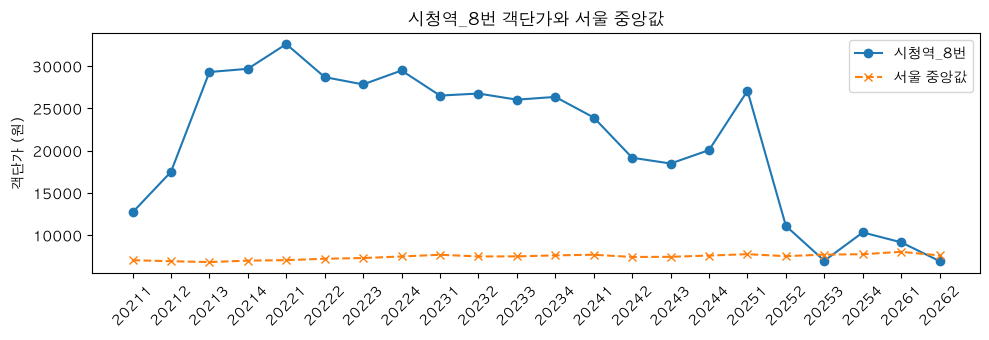

In [11]:
seoul_ticket = df.groupby('기준_년분기_코드')['객단가'].median()

labels = [str(q) for q in city['기준_년분기_코드']]
plt.figure(figsize=(10, 3.5))
plt.plot(labels, city['객단가'].values, marker='o', label='시청역_8번')
plt.plot(labels, seoul_ticket.values, marker='x', linestyle='--', label='서울 중앙값')
plt.xticks(rotation=45)
plt.ylabel('객단가 (원)')
plt.title('시청역_8번 객단가와 서울 중앙값')
plt.legend()
plt.tight_layout()
plt.show()

#### 코드 읽기
- `seoul_ticket = ...`: 분기마다 서울 전체 객단가 중앙값을 구합니다.
- `plt.plot(x, y, marker='o', label=...)`: 선 그래프를 그리고 점마다 동그라미를 찍습니다. `label`은 범례에 나올 이름입니다.
- `linestyle='--'`: 비교용 선은 점선으로 그려 구분합니다.
- `plt.legend()`: `label`로 붙인 이름을 범례로 보여 줍니다.
- 시청역_8번은 22개 분기가 다 있어서 x축 라벨을 그대로 같이 씁니다. 분기가 빠진 상권이었다면 두 선의 x 위치가 어긋나니 조심해야 합니다.

서울 중앙값은 22개 분기 동안 6,800~8,000원 사이에서 거의 그대로입니다. 시청역_8번만 2025년 2분기에 크게 꺾였으니 이 상권에서 결제가 잡히는 방식이 바뀐 것으로 보입니다. 예를 들어 단체·법인 주문 위주로 잡히던 결제에 개인 결제가 더 많이 잡히기 시작했을 수 있습니다. 이것도 확인할 방법이 없어서 가능성으로만 둡니다.

점포당 매출은 금액 ÷ 점포 수라서 건수가 바뀐 영향을 받지 않습니다. 객단가를 쓰는 분석을 하게 되면 이 상권은 따로 봐야 합니다.

## 정리

| 문제 | 확인 결과 | 원인 판단 |
|---|---|---|
| 저매출 53곳 | 객단가는 보통, 결제 건수가 다른 상권의 40분의 1. 40곳은 점포당 하루 1건 미만 | 수집 한계 (결제가 거의 안 잡힘) |
| 저매출 53곳 | 25곳은 절반이 안 되는 분기에만 저매출, 분기마다 39~64곳씩 꾸준히 나옴 | 분기마다 같은 규칙으로 다뤄야 함 |
| 시청역_8번 | 22개 분기 내내 서울 중앙값의 18~28배, 주중·오전 비중이 오피스 상권과 맞음 | 진짜 값으로 봄 |
| 시청역_8번 | 2025년 2분기부터 객단가가 절반 이하로 떨어지고 건수가 늘어남 | 결제 집계 방식 변화로 추정 (점포당 매출에는 영향 없음) |

## 처리 결정 (2026-11-11)

위 결과를 보고 가설 검증을 하기 전에 정했습니다.

| 문제 | 처리 | 같이 볼 것 |
|---|---|---|
| 결제가 거의 안 잡히는 줄 | 점포당 분기 결제 건수 90건 미만(하루 1건 미만)인 줄을 분기마다 본 분석에서 뺌. 2026Q2는 50곳 | 뺀 줄을 포함했을 때 결과 |
| 시청역_8번 | 남김 | 이 상권을 뺐을 때 결과 |
| 점포당 매출 분포 | 상관과 회귀에는 자연로그를 씀 | 스피어만(H5)은 순위라 영향 없음 |

저매출 기준(100만 원)을 그대로 쓰지 않고 건수 기준으로 바꾼 이유는 원인이 결제가 거의 안 잡히는 데 있기 때문입니다. 금액 기준으로 자르면 객단가가 높아서 금액만 넘긴 상권(10곳)은 남고, 건수는 충분한데 금액이 낮은 상권(13곳)은 빠집니다.

## 확인 질문

<details>
<summary>1. 저매출의 원인을 금액 기록 문제로 보지 않은 근거는?</summary>

객단가 중앙값이 나머지 상권과 거의 같고(7,659원, 7,559원) 결제 건수만 40분의 1 수준이라서입니다. 금액이 잘못 기록됐다면 객단가가 이상하게 나왔을 겁니다.
</details>

<details>
<summary>2. 이 노트북에서 직장인구와 매출의 상관을 보지 않은 이유는?</summary>

처리 규칙을 가설 검증 결과를 보고 정하지 않기 위해서입니다. 결과를 먼저 보면 원하는 결론이 나오는 쪽으로 규칙을 고르게 될 수 있습니다.
</details>

<details>
<summary>3. 2026년 2분기 53곳 목록으로 모든 분기를 지우면 안 되는 이유는?</summary>

25곳은 절반이 안 되는 분기에만 저매출이라 분기마다 기준을 넘었다 말았다 합니다. 목록으로 지우면 멀쩡한 분기까지 같이 지워집니다.
</details>

<details>
<summary>4. 시청역_8번 객단가가 2025년에 꺾였는데 점포당 매출은 그대로 써도 되는 이유는?</summary>

바뀐 건 결제 건수이고 매출 금액은 그대로입니다. 점포당 매출은 금액을 점포 수로 나눈 값이라 건수와 상관이 없습니다.
</details>

<details>
<summary>5. df[df['매출'].notna()] 뒤에 .copy()를 붙인 이유는?</summary>

걸러 낸 결과를 새 데이터프레임으로 만들기 위해서입니다. 안 붙이면 원래 데이터의 일부를 가리키는 상태라서 컬럼을 추가할 때 pandas가 SettingWithCopyWarning 경고를 띄울 수 있습니다.
</details>